# Le fonctionnement de GAN 
compose de 2 RN qui travaillent l un contre l autre :
- generator : qui cree de fausses images
- discriminator : qui essaie de distinguer les vraies images des fausses 

In [1]:

import os
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms
from torchvision.utils import make_grid

print("PyTorch version :", torch.__version__)
print("GPU disponible :", torch.cuda.is_available())

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device utilisé :", device)


PyTorch version : 2.11.0+cu130
GPU disponible : True
Device utilisé : cuda


# Explorer dossiers du datset


In [13]:
import os

dataset_path = "/kaggle/input/datasets/bryanb/abstract-art-gallery"

print("Contenu du dossier :")
print(os.listdir(dataset_path))

Contenu du dossier :
['Abstract_gallery', 'Abstract_gallery_2']


In [14]:
import os

for folder in ["Abstract_gallery", "Abstract_gallery_2"]:

    folder_path = os.path.join(dataset_path, folder)

    print(f"\nDossier : {folder}")
    print("Existe :", os.path.exists(folder_path))

    for root, dirs, files in os.walk(folder_path):
        print("\nChemin :", root)
        print("Nombre de fichiers :", len(files))
        print("Exemples :", files[:10])


Dossier : Abstract_gallery
Existe : True

Chemin : /kaggle/input/datasets/bryanb/abstract-art-gallery/Abstract_gallery
Nombre de fichiers : 0
Exemples : []

Chemin : /kaggle/input/datasets/bryanb/abstract-art-gallery/Abstract_gallery/Abstract_gallery
Nombre de fichiers : 2782
Exemples : ['Abstract_image_0.jpg', 'Abstract_image_1.jpg', 'Abstract_image_10.jpg', 'Abstract_image_100.jpg', 'Abstract_image_1000.jpg', 'Abstract_image_1001.jpg', 'Abstract_image_1002.jpg', 'Abstract_image_1003.jpg', 'Abstract_image_1004.jpg', 'Abstract_image_1005.jpg']

Dossier : Abstract_gallery_2
Existe : True

Chemin : /kaggle/input/datasets/bryanb/abstract-art-gallery/Abstract_gallery_2
Nombre de fichiers : 0
Exemples : []

Chemin : /kaggle/input/datasets/bryanb/abstract-art-gallery/Abstract_gallery_2/Abstract_gallery_2
Nombre de fichiers : 90
Exemples : ['Abstract_image_2782.jpg', 'Abstract_image_2783.jpg', 'Abstract_image_2784.jpg', 'Abstract_image_2785.jpg', 'Abstract_image_2786.jpg', 'Abstract_image_27

structure du dataset : 
- Abstract_gallery/ Abstract_gallery/2782 images (.jpg)
- Abstract_gallery_2/Abstract_gallery_2/90 images (.jpg)
  
----> Nombre total : 2 872 images

## Examiner les images du dataset 
- dim images
- couleurs
- lisibilite ...

In [16]:
from PIL import Image
import os

image_paths = []

folders = [
    os.path.join(dataset_path, "Abstract_gallery", "Abstract_gallery"),
    os.path.join(dataset_path, "Abstract_gallery_2", "Abstract_gallery_2")
]

for folder in folders:
    for filename in os.listdir(folder):
        if filename.lower().endswith((".jpg", ".jpeg", ".png")):
            image_paths.append(os.path.join(folder, filename))

print("Nombre total d'images :", len(image_paths))

# Examiner les premieres images
for path in image_paths[:10]:
    img = Image.open(path)

    print(
        "Image :", os.path.basename(path),
        "| Dimensions :", img.size,
        "| Mode :", img.mode
    )

Nombre total d'images : 2872
Image : Abstract_image_0.jpg | Dimensions : (1280, 920) | Mode : RGB
Image : Abstract_image_1.jpg | Dimensions : (534, 747) | Mode : RGB
Image : Abstract_image_10.jpg | Dimensions : (750, 746) | Mode : RGB
Image : Abstract_image_100.jpg | Dimensions : (800, 1085) | Mode : RGB
Image : Abstract_image_1000.jpg | Dimensions : (500, 434) | Mode : RGB
Image : Abstract_image_1001.jpg | Dimensions : (500, 396) | Mode : RGB
Image : Abstract_image_1002.jpg | Dimensions : (510, 419) | Mode : RGB
Image : Abstract_image_1003.jpg | Dimensions : (1024, 768) | Mode : RGB
Image : Abstract_image_1004.jpg | Dimensions : (1022, 1024) | Mode : RGB
Image : Abstract_image_1005.jpg | Dimensions : (540, 480) | Mode : RGB


- les images ont des dim differents : horizontales, verticales , carrees
- dont toutes en mode RGB ( 3 canaux )
-  donc ca ncessite qu on redimmensione toutes les images a une taille identique pour les transmettre au reseau neuronal 

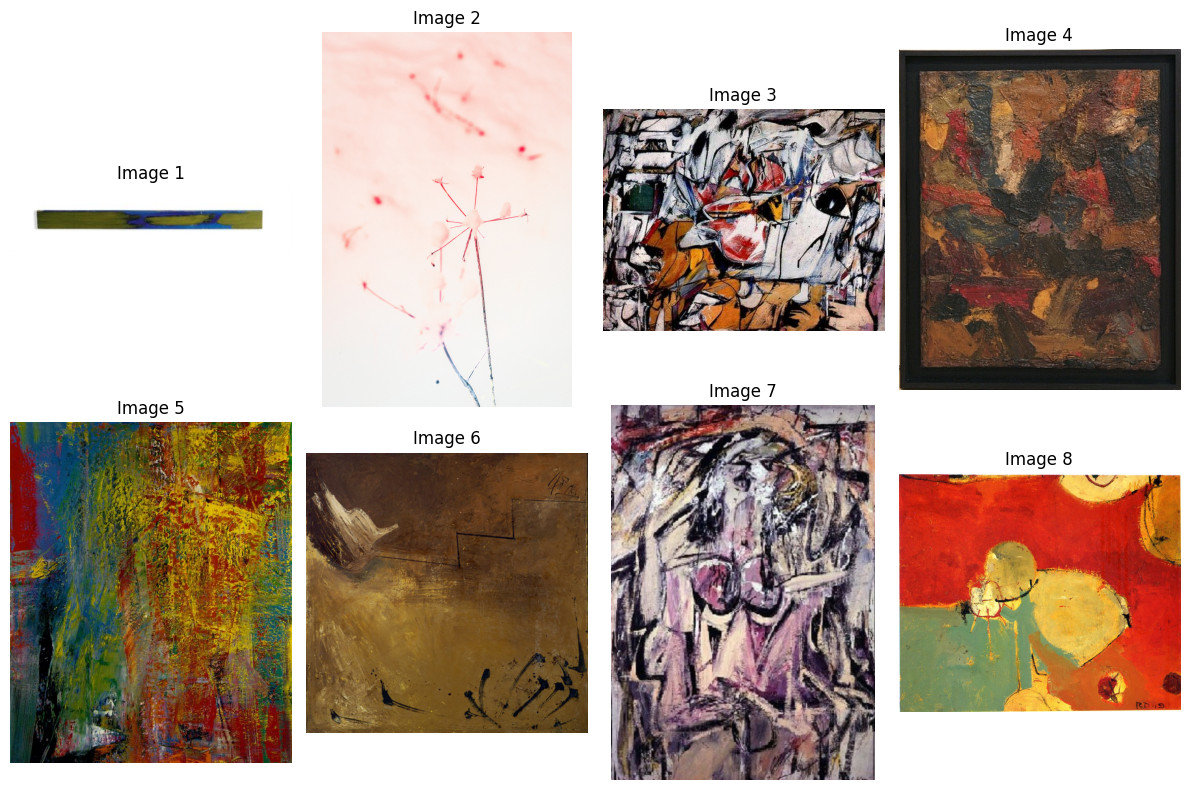

In [17]:
import matplotlib.pyplot as plt
import random

selected_images = random.sample(image_paths, 8)

plt.figure(figsize=(12, 8))

for i, path in enumerate(selected_images):
    img = Image.open(path).convert("RGB")

    plt.subplot(2, 4, i + 1)
    plt.imshow(img)
    plt.axis("off")
    plt.title(f"Image {i+1}")

plt.tight_layout()
plt.show()

### Pretraitement des images 
- redimmensionner toutes les images : 64 x 64
- les convertir en tenseurs entre 0 et 1 
- normaliser les pixels entre -1 et 1 :puisque on va use fct activation tanh  qui produit des valeurs entre -1 et 1 

In [18]:
# creer transformation 
from torchvision import transforms

image_size = 64

transform = transforms.Compose([
    transforms.Resize((image_size, image_size)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.5, 0.5, 0.5), # on applique meme mnormalisation a chacun des 3 canaux 
        std=(0.5, 0.5, 0.5)
    )
])

In [19]:
# creer le dataset personnalise 
from torch.utils.data import Dataset, DataLoader
from PIL import Image

class AbstractArtDataset(Dataset):

    def __init__(self, image_paths, transform=None):
        self.image_paths = image_paths
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, index):
        image_path = self.image_paths[index]

        image = Image.open(image_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image

In [20]:
dataset = AbstractArtDataset(
    image_paths=image_paths,
    transform=transform
)

print("Nombre d'images :", len(dataset))

Nombre d'images : 2872


In [21]:
# creer le dataloader  : qui permet de charger les images par lots  pendant training 
batch_size = 64

dataloader = DataLoader(
    dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

print("Nombre de batches :", len(dataloader))

Nombre de batches : 45


In [22]:
# verification
images = next(iter(dataloader))

print("Dimensions du batch :", images.shape)
print("Valeur minimale :", images.min().item())
print("Valeur maximale :", images.max().item())

Dimensions du batch : torch.Size([64, 3, 64, 64])
Valeur minimale : -1.0
Valeur maximale : 1.0


- 64 nbre d images dans le batch
- 3 : 3 canaux RGB
- 64 x 64  hauteur et largeur des images 

### afficher les images apres pretraitement 

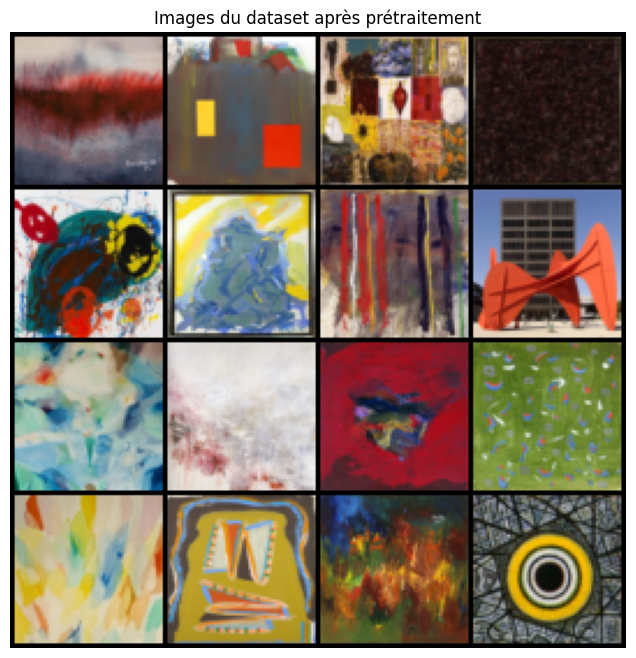

In [23]:
import matplotlib.pyplot as plt
from torchvision.utils import make_grid

# recuperer un batch
images = next(iter(dataloader))

# Inverser la normalisation [-1, 1] vers [0, 1]
images_display = (images + 1) / 2

# creer une grille de 16 images
grid = make_grid(images_display[:16], nrow=4)

# Affichage
plt.figure(figsize=(8, 8))
plt.imshow(grid.permute(1, 2, 0))
plt.axis("off")
plt.title("Images du dataset après prétraitement")
plt.show()

### Creer le Generator et Discriminator 
- pour generator : un vecteur de bruit aleatoire de dim 100 sortie : image RGB de 64 x 64
- pour le discriminator : image de 64 x 64 pixels  sortie : score indique si image fake or not

In [27]:
# implementer du generator 
import torch
import torch.nn as nn

class Generator(nn.Module):

    def __init__(self, latent_dim=100, ngf=64, nc=3):
        super(Generator, self).__init__()

        self.main = nn.Sequential(

            # Bruit : (100, 1, 1)
            # Sortie : (512, 4, 4)
            nn.ConvTranspose2d(  # augmente progressivemnt resolution de image 
                latent_dim, ngf * 8,
                kernel_size=4, stride=1, padding=0, bias=False
            ),
            nn.BatchNorm2d(ngf * 8), # stabilise les activations et facilite entrainemnt 
            nn.ReLU(True),

            # (512, 4, 4) -> (256, 8, 8)
            nn.ConvTranspose2d(
                ngf * 8, ngf * 4,
                kernel_size=4, stride=2, padding=1, bias=False
            ),
            nn.BatchNorm2d(ngf * 4),
            nn.ReLU(True),

            # (256, 8, 8) -> (128, 16, 16)
            nn.ConvTranspose2d(
                ngf * 4, ngf * 2,
                kernel_size=4, stride=2, padding=1, bias=False
            ),
            nn.BatchNorm2d(ngf * 2),
            nn.ReLU(True),

            # (128, 16, 16) -> (64, 32, 32)
            nn.ConvTranspose2d(
                ngf * 2, ngf,
                kernel_size=4, stride=2, padding=1, bias=False
            ),
            nn.BatchNorm2d(ngf),
            nn.ReLU(True),

            # (64, 32, 32) -> (3, 64, 64)
            nn.ConvTranspose2d(
                ngf, nc,
                kernel_size=4, stride=2, padding=1, bias=False
            ),
            nn.Tanh() # produit les valeurs finales entre -1 et 1 
        )

    def forward(self, z):
        return self.main(z)

In [29]:
# implementer le discriminator 
class Discriminator(nn.Module):

    def __init__(self, nc=3, ndf=64):
        super(Discriminator, self).__init__()

        self.main = nn.Sequential(

            # (3, 64, 64) -> (64, 32, 32)
            nn.Conv2d(
                nc, ndf,
                kernel_size=4, stride=2, padding=1, bias=False
            ),
            nn.LeakyReLU(0.2, inplace=True),

            # (64, 32, 32) -> (128, 16, 16)
            nn.Conv2d(
                ndf, ndf * 2,
                kernel_size=4, stride=2, padding=1, bias=False
            ),
            nn.BatchNorm2d(ndf * 2),
            nn.LeakyReLU(0.2, inplace=True),

            # (128, 16, 16) -> (256, 8, 8)
            nn.Conv2d(
                ndf * 2, ndf * 4,
                kernel_size=4, stride=2, padding=1, bias=False
            ),
            nn.BatchNorm2d(ndf * 4),
            nn.LeakyReLU(0.2, inplace=True),

            # (256, 8, 8) -> (512, 4, 4)
            nn.Conv2d(
                ndf * 4, ndf * 8,
                kernel_size=4, stride=2, padding=1, bias=False
            ),
            nn.BatchNorm2d(ndf * 8),
            nn.LeakyReLU(0.2, inplace=True),

            # (512, 4, 4) -> (1, 1, 1)
            nn.Conv2d(
                ndf * 8, 1,
                kernel_size=4, stride=1, padding=0, bias=False
            )
        )

    def forward(self, x):
        return self.main(x).view(-1)

In [30]:
# initialiser les piods 
def weights_init(m):

    classname = m.__class__.__name__

    if classname.find("Conv") != -1:
        nn.init.normal_(m.weight.data, 0.0, 0.02)

    elif classname.find("BatchNorm") != -1:
        nn.init.normal_(m.weight.data, 1.0, 0.02)
        nn.init.constant_(m.bias.data, 0)

In [31]:
# creer models et envoyer au gpu 
# Paramètres
latent_dim = 100 # dim du vecteur de bruit aleatoire 
ngf = 64 # nbre de filtres de base dnas le generator 
nc = 3 # nbre de canaux de sortie (RGB)
ndf = 64

# Création du Generator
netG = Generator(
    latent_dim=latent_dim,
    ngf=ngf,
    nc=nc
).to(device)

# Création du Discriminator
netD = Discriminator(
    nc=nc,
    ndf=ndf
).to(device)

# Initialisation des poids
netG.apply(weights_init)
netD.apply(weights_init)

print("Generator et Discriminator créés avec succès !")
print("Device :", device)

Generator et Discriminator créés avec succès !
Device : cuda


In [32]:
# verifier le fonctionnement des 2 reseaux

# generer un bruit aleatoire
noise = torch.randn(
    batch_size,
    latent_dim,
    1,
    1,
    device=device
)

# generer des images
fake_images = netG(noise)

print("Bruit en entrée :", noise.shape)
print("Images générées :", fake_images.shape)

Bruit en entrée : torch.Size([64, 100, 1, 1])
Images générées : torch.Size([64, 3, 64, 64])


- 64 : 	Nombre de vecteurs de bruit
- 100 :  Nombre de valeurs dans chaque vecteur (Chaque image sera donc est creer a partir un vecteur contenant 100 valeurs aleatoires.)
- 1  : hauteur initiale
- 1  : largeur initiale

In [33]:
# Passer les images générées au Discriminator
output = netD(fake_images)

print("Images en entrée :", fake_images.shape)
print("Sortie du Discriminator :", output.shape)

Images en entrée : torch.Size([64, 3, 64, 64])
Sortie du Discriminator : torch.Size([64])



- 64	Nombre d'images générées
- 3	Canaux RGB
- 64	Hauteur
-  64	Largeur

In [37]:
with torch.no_grad():
    noise = torch.randn(16, latent_dim, 1, 1, device=device)
    generated_images = netG(noise)

print("Dimensions :", generated_images.shape)
print("Minimum :", generated_images.min().item())
print("Maximum :", generated_images.max().item())
print("Device :", generated_images.device)

Dimensions : torch.Size([16, 3, 64, 64])
Minimum : -0.8376091718673706
Maximum : 0.8260506987571716
Device : cuda:0


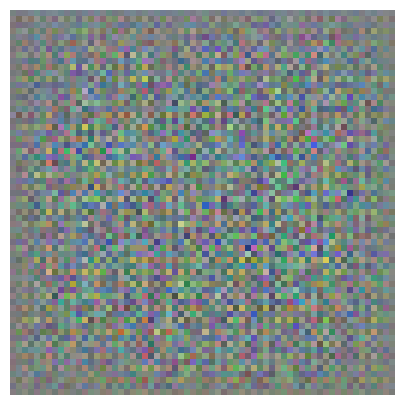

In [38]:
import matplotlib.pyplot as plt

with torch.no_grad():
    noise = torch.randn(1, latent_dim, 1, 1, device=device)
    generated_image = netG(noise)

# Normalisation pour l'affichage
generated_image = (generated_image[0].cpu() + 1) / 2

# Conversion du format [C, H, W] vers [H, W, C]
generated_image = generated_image.permute(1, 2, 0)

plt.figure(figsize=(5, 5))
plt.imshow(generated_image)
plt.axis("off")
plt.show()

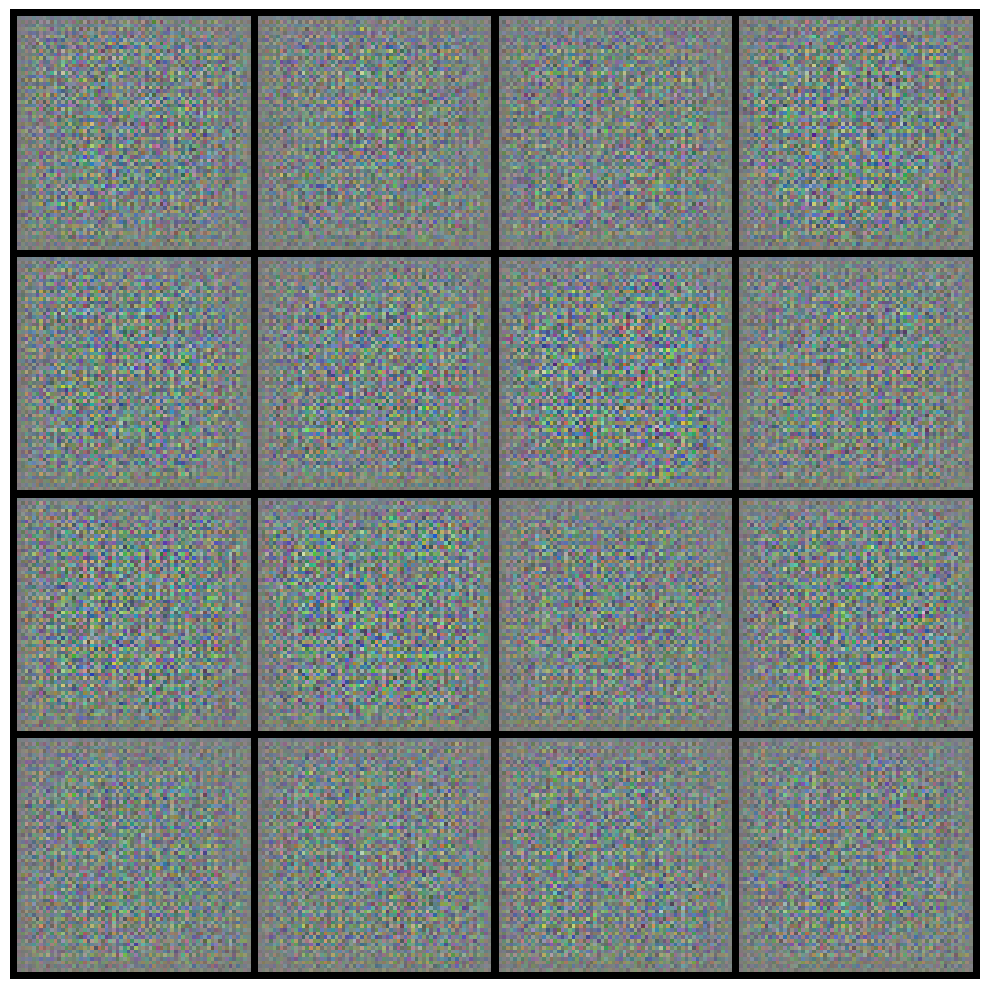

In [39]:
import matplotlib.pyplot as plt
from torchvision.utils import make_grid

with torch.no_grad():
    noise = torch.randn(16, latent_dim, 1, 1, device=device)
    generated_images = netG(noise)

generated_images = generated_images.cpu()

# Ramener les pixels vers [0, 1]
generated_images = (generated_images + 1) / 2

grid = make_grid(generated_images, nrow=4, padding=2)

plt.figure(figsize=(10, 10))
plt.imshow(grid.permute(1, 2, 0).numpy())
plt.axis("off")
plt.tight_layout()
plt.show()

A. Loss_D — perte du Discriminator
Le Discriminator doit apprendre à distinguer :
- Les vraies images provenant de notre dataset de 2 872 peintures abstraites.
- Les fausses images produites par le Generator.
B. Loss_G — perte du Generator
Le Generator a un objectif différent : il veut tromper le Discriminator.
Il produit des images que le Discriminator doit considérer comme réelles.

In [40]:
import torch.nn as nn

# Fonction de perte utilisee par le Generator et le Discriminator
criterion = nn.BCEWithLogitsLoss()

In [41]:
import torch.optim as optim

# learning rate
lr = 0.0002

# Optimiseur du Generator
optimizerG = optim.Adam(
    netG.parameters(),
    lr=lr,
    betas=(0.5, 0.999)
)

# Optimiseur du Discriminator
optimizerD = optim.Adam(
    netD.parameters(),
    lr=lr,
    betas=(0.5, 0.999)
)

In [42]:
print("Fonction de perte :", criterion)
print("Optimiseur Generator :", optimizerG)
print("Optimiseur Discriminator :", optimizerD)

Fonction de perte : BCEWithLogitsLoss()
Optimiseur Generator : Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.5, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0002
    maximize: False
    weight_decay: 0
)
Optimiseur Discriminator : Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.5, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0002
    maximize: False
    weight_decay: 0
)


- Entraîner le Discriminator pour reconnaître les vraies et les fausses images.
- Entraîner le Generator pour produire des images capables de tromper le Discriminator.
- Répéter ces deux opérations pour chaque batch, pendant plusieurs epochs.

In [43]:
# Listes pour stocker les pertes pendant training
G_losses = []
D_losses = []

# Bruit fixe pour visualiser evolution des images generees
fixed_noise = torch.randn(16, latent_dim, 1, 1, device=device)

# Nombre d'epochs
num_epochs = 50

print("Nombre d'epochs :", num_epochs)
print("Bruit fixe :", fixed_noise.shape)
print("Prêt pour l'entraînement !")

Nombre d'epochs : 50
Bruit fixe : torch.Size([16, 100, 1, 1])
Prêt pour l'entraînement !


### Entrainer le D & G

In [45]:

# Mode entraînement
netG.train()
netD.train()

for epoch in range(num_epochs):

    for i, real_images in enumerate(dataloader):

        b_size = real_images.size(0)
        real_images = real_images.to(device)

        real_labels = torch.ones(b_size, device=device)
        fake_labels = torch.zeros(b_size, device=device)

        # =====================================
        # 1. ENTRAINEMENT DU DISCRIMINATOR
        # =====================================

        optimizerD.zero_grad()

        output_real = netD(real_images)
        loss_real = criterion(output_real, real_labels)

        noise = torch.randn(b_size, latent_dim, 1, 1, device=device)
        fake_images = netG(noise)

        output_fake = netD(fake_images.detach())
        loss_fake = criterion(output_fake, fake_labels)

        loss_D = loss_real + loss_fake

        loss_D.backward()
        optimizerD.step()

        # =====================================
        # 2. ENTRAINEMENT DU GENERATOR
        # =====================================

        optimizerG.zero_grad()

        noise = torch.randn(b_size, latent_dim, 1, 1, device=device)
        fake_images = netG(noise)

        output = netD(fake_images)
        loss_G = criterion(output, real_labels)

        loss_G.backward()
        optimizerG.step()

        # Enregistrer les pertes
        G_losses.append(loss_G.item())
        D_losses.append(loss_D.item())

    print(f"Epoch [{epoch+1}/{num_epochs}] terminée")


Epoch [1/50] terminée
Epoch [2/50] terminée
Epoch [3/50] terminée
Epoch [4/50] terminée
Epoch [5/50] terminée
Epoch [6/50] terminée
Epoch [7/50] terminée
Epoch [8/50] terminée
Epoch [9/50] terminée
Epoch [10/50] terminée
Epoch [11/50] terminée
Epoch [12/50] terminée
Epoch [13/50] terminée
Epoch [14/50] terminée
Epoch [15/50] terminée
Epoch [16/50] terminée
Epoch [17/50] terminée
Epoch [18/50] terminée
Epoch [19/50] terminée
Epoch [20/50] terminée
Epoch [21/50] terminée
Epoch [22/50] terminée
Epoch [23/50] terminée
Epoch [24/50] terminée
Epoch [25/50] terminée
Epoch [26/50] terminée
Epoch [27/50] terminée
Epoch [28/50] terminée
Epoch [29/50] terminée
Epoch [30/50] terminée
Epoch [31/50] terminée
Epoch [32/50] terminée
Epoch [33/50] terminée
Epoch [34/50] terminée
Epoch [35/50] terminée
Epoch [36/50] terminée
Epoch [37/50] terminée
Epoch [38/50] terminée
Epoch [39/50] terminée
Epoch [40/50] terminée
Epoch [41/50] terminée
Epoch [42/50] terminée
Epoch [43/50] terminée
Epoch [44/50] termin

In [50]:
additional_epochs = 50

G_losses_2 = []
D_losses_2 = []

for epoch in range(additional_epochs):

    for i, real_images in enumerate(dataloader):

        b_size = real_images.size(0)
        real_images = real_images.to(device)

        real_labels = torch.ones(b_size, device=device)
        fake_labels = torch.zeros(b_size, device=device)

        # =====================================
        # Entraîner le Discriminator
        # =====================================
        optimizerD.zero_grad()

        output_real = netD(real_images)
        loss_real = criterion(output_real, real_labels)

        noise = torch.randn(b_size, latent_dim, 1, 1, device=device)
        fake_images = netG(noise)

        output_fake = netD(fake_images.detach())
        loss_fake = criterion(output_fake, fake_labels)

        loss_D = loss_real + loss_fake
        loss_D.backward()
        optimizerD.step()

        # =====================================
        # Entraîner le Generator
        # =====================================
        optimizerG.zero_grad()

        noise = torch.randn(b_size, latent_dim, 1, 1, device=device)
        fake_images = netG(noise)

        output = netD(fake_images)
        loss_G = criterion(output, real_labels)

        loss_G.backward()
        optimizerG.step()

        G_losses_2.append(loss_G.item())
        D_losses_2.append(loss_D.item())

    print(f"Epoch [{epoch + 51}/100] terminée")


G_losses_epoch_2 = np.array(G_losses_2).reshape(
    additional_epochs, len(dataloader)
).mean(axis=1)

D_losses_epoch_2 = np.array(D_losses_2).reshape(
    additional_epochs, len(dataloader)
).mean(axis=1)

print("Generator Loss après 100 epochs :", G_losses_epoch_2[-1])
print("Discriminator Loss après 100 epochs :", D_losses_epoch_2[-1])

Epoch [51/100] terminée
Epoch [52/100] terminée
Epoch [53/100] terminée
Epoch [54/100] terminée
Epoch [55/100] terminée
Epoch [56/100] terminée
Epoch [57/100] terminée
Epoch [58/100] terminée
Epoch [59/100] terminée
Epoch [60/100] terminée
Epoch [61/100] terminée
Epoch [62/100] terminée
Epoch [63/100] terminée
Epoch [64/100] terminée
Epoch [65/100] terminée
Epoch [66/100] terminée
Epoch [67/100] terminée
Epoch [68/100] terminée
Epoch [69/100] terminée
Epoch [70/100] terminée
Epoch [71/100] terminée
Epoch [72/100] terminée
Epoch [73/100] terminée
Epoch [74/100] terminée
Epoch [75/100] terminée
Epoch [76/100] terminée
Epoch [77/100] terminée
Epoch [78/100] terminée
Epoch [79/100] terminée
Epoch [80/100] terminée
Epoch [81/100] terminée
Epoch [82/100] terminée
Epoch [83/100] terminée
Epoch [84/100] terminée
Epoch [85/100] terminée
Epoch [86/100] terminée
Epoch [87/100] terminée
Epoch [88/100] terminée
Epoch [89/100] terminée
Epoch [90/100] terminée
Epoch [91/100] terminée
Epoch [92/100] t

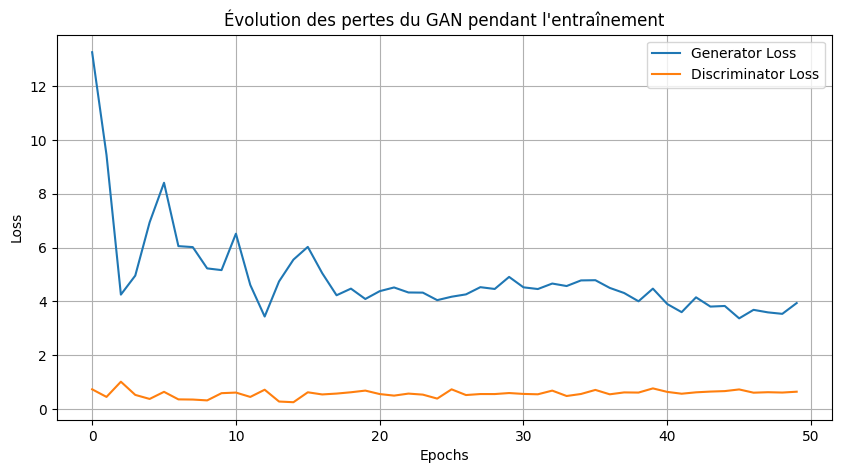

In [51]:
import matplotlib.pyplot as plt
import numpy as np

# Calculer la perte moyenne de chaque epoch
G_losses_epoch = np.array(G_losses).reshape(num_epochs, len(dataloader)).mean(axis=1)
D_losses_epoch = np.array(D_losses).reshape(num_epochs, len(dataloader)).mean(axis=1)

# Tracer les courbes
plt.figure(figsize=(10, 5))

plt.plot(G_losses_epoch, label="Generator Loss")
plt.plot(D_losses_epoch, label="Discriminator Loss")

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Évolution des pertes du GAN pendant l'entraînement")
plt.legend()
plt.grid(True)

plt.show()

Les résultats montrent que les deux réseaux ont appris pendant les 50 epochs :
- Le Generator a connu une amélioration importante.
- Le Discriminator a également amélioré ses capacités de classification.
- Les deux réseaux continuent à avoir des erreurs, ce qui est normal dans un apprentissage adversarial.

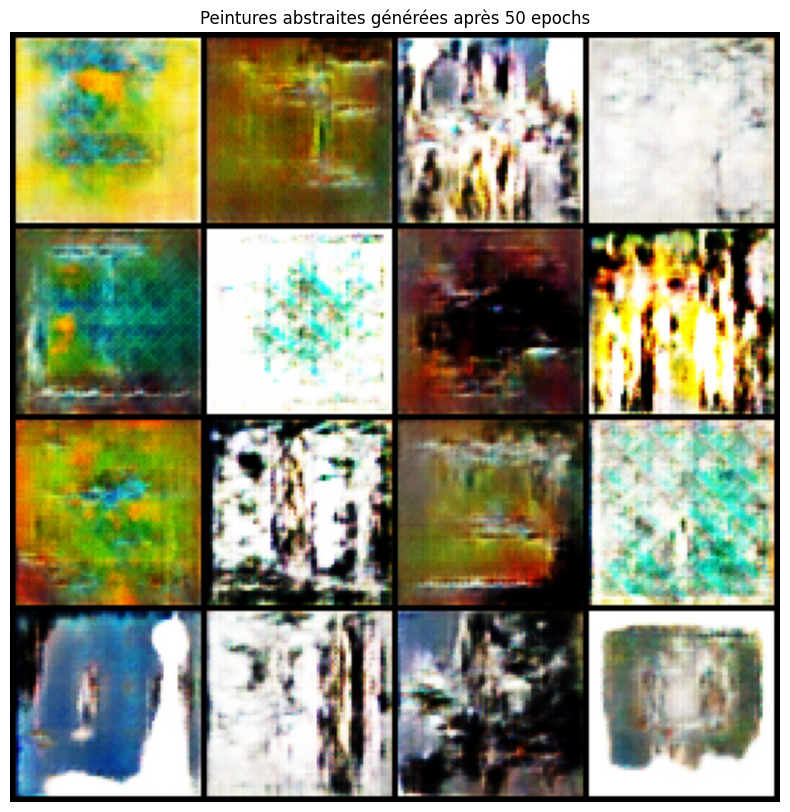

In [52]:
import matplotlib.pyplot as plt
from torchvision.utils import make_grid

# Mettre le Generator en mode évaluation
netG.eval()

# Générer 16 nouvelles images
with torch.no_grad():
    noise = torch.randn(16, latent_dim, 1, 1, device=device)
    generated_images = netG(noise)

# Revenir de [-1, 1] à [0, 1]
generated_images = (generated_images + 1) / 2

# Créer une grille de 16 images
grid = make_grid(generated_images.cpu(), nrow=4)

# Afficher les images
plt.figure(figsize=(10, 10))
plt.imshow(grid.permute(1, 2, 0))
plt.axis("off")
plt.title("Peintures abstraites générées après 50 epochs")
plt.show()

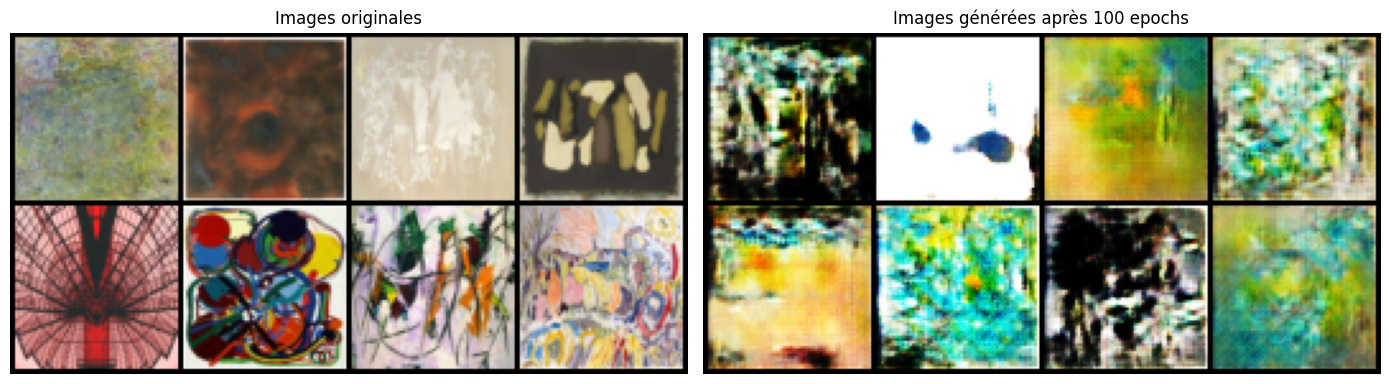

In [55]:
# Récupérer 8 images originales
real_images = next(iter(dataloader))[:8]

# Générer 8 nouvelles images
netG.eval()

with torch.no_grad():
    noise = torch.randn(8, latent_dim, 1, 1, device=device)
    fake_images = netG(noise)

# Ramener les valeurs de [-1, 1] vers [0, 1]
real_images = (real_images.cpu() + 1) / 2
fake_images = (fake_images.cpu() + 1) / 2

# Créer les grilles
real_grid = make_grid(real_images, nrow=4)
fake_grid = make_grid(fake_images, nrow=4)

# Afficher la comparaison
fig, axes = plt.subplots(1, 2, figsize=(14, 7))

axes[0].imshow(real_grid.permute(1, 2, 0))
axes[0].set_title("Images originales")
axes[0].axis("off")

axes[1].imshow(fake_grid.permute(1, 2, 0))
axes[1].set_title("Images générées après 100 epochs")
axes[1].axis("off")

plt.tight_layout()
plt.show()

Les images générées montrent que le Generator a réussi à apprendre certaines caractéristiques des peintures abstraites, notamment les couleurs, les formes et les compositions. Les résultats obtenus sont globalement satisfaisants, même si les images présentent encore un léger flou et un manque de précision dans certains détails par rapport aux images originales.

Ces résultats montrent que le modèle a appris à produire de nouvelles compositions inspirées du dataset, mais que la qualité visuelle peut encore être améliorée en augmentant la durée d'entraînement, en ajustant les hyperparamètres et en optimisant l'architecture du GAN.